# 1.1 EDA: use by year, time of day, season and household type

**Question.** How much energy do SERL households use, when in the day and year, how unequal is use between households, and how does it differ by dwelling and household? 2020–2023, whole sample unless stated.

**Data.** SERL Study 8963 daily-statistics file (yearly and monthly rows) and the four half-hourly files, read with `serl_energy.dataset`.

**Method.** Every number comes from **one group of households in one unit**: SERL rows stack overlapping groups (whole sample, heating fuel, PV, region, EPC, …) and three units per quantity, and `serl_energy.dataset` refuses to mix them. Confidence intervals use SERL's standard errors (uncertainty of the mean, not the spread between households).

**Outputs.** Figures in `reports/figures/1.1-eda-univariate/`, tables in `reports/tables/1.1-eda-univariate/`.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from serl_energy import dataset as serl, plots
from serl_energy.labels import SEGMENT_NAMES, level_label, ordered_levels
from serl_energy.plots import COLORS, INK, SEQUENTIAL_CMAP, YEAR_COLORS
from serl_energy.reporting import Reporter

warnings.filterwarnings("ignore", category=UserWarning)
plots.use_theme()
reporter = Reporter("1.1-eda-univariate")

yearly = serl.load_yearly()
monthly = serl.load_monthly(serl.CLEAN_CSV)
hh = serl.load_half_hourly()
QUANTITIES = ["Electricity imports", "Electricity exports", "Electricity net", "Gas", "Gas + electricity imports"]
MAIN = {"Electricity imports": COLORS["electricity"], "Gas": COLORS["gas"]}
YEARS = list(serl.YEARS)
print(f"yearly rows {len(yearly):,}, monthly rows {len(monthly):,}, half-hourly rows {len(hh):,}")

yearly rows 40,860, monthly rows 490,320, half-hourly rows 1,961,280


## 1. Use per household by year

Electricity and gas differ fourfold in level, so both are shown as an index (2020 = 100) on one axis; the labels give the actual kWh/day. **Look for:** both fell by about a fifth, almost all of it in 2022.


Mean kWh/day per household, whole sample
year                        2020   2021   2022   2023  change_2020_2023_pct
quantity                                                                   
Electricity imports        10.94  10.11   8.78   8.51                -22.14
Electricity exports         0.18   0.29   0.02   0.01                -92.85
Electricity net            10.76   9.82   8.75   8.50                -21.00
Gas                        36.85  38.67  30.44  29.06                -21.14
Gas + electricity imports  44.32  44.59  36.29  34.77                -21.55


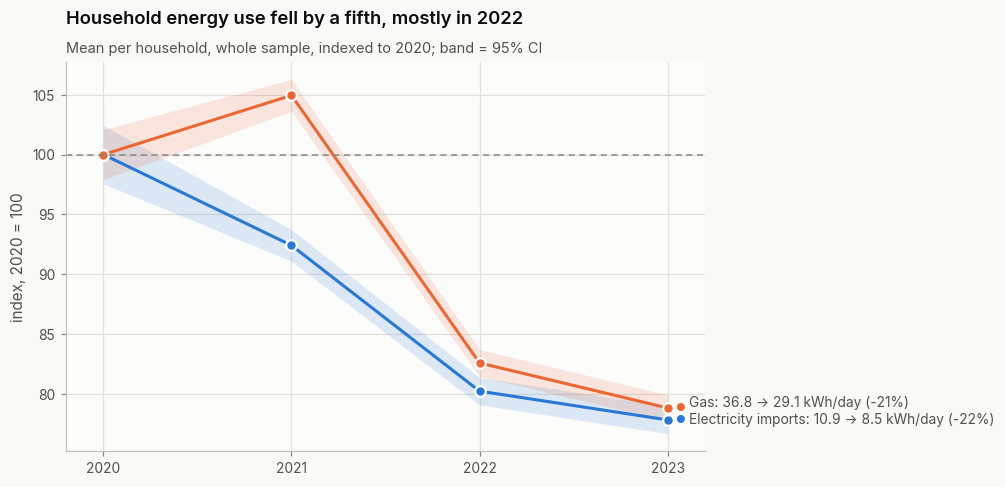

In [2]:
rows = []
for q in QUANTITIES:
    s = serl.select_slice(yearly, q, "kWh/day").set_index("year")
    for y, r in s.iterrows():
        rows.append({"quantity": q, "year": y, "mean_kwh_per_day": r["mean"],
                     "ci95_low": r["mean"] - 1.96 * r["standard_error_mean"],
                     "ci95_high": r["mean"] + 1.96 * r["standard_error_mean"], "households": int(r["n_rounded"])})
annual = pd.DataFrame(rows)
wide = annual.pivot(index="quantity", columns="year", values="mean_kwh_per_day").loc[QUANTITIES]
wide["change_2020_2023_pct"] = 100 * (wide[2023] / wide[2020] - 1)
print("Mean kWh/day per household, whole sample")
print(wide.round(2).to_string())
reporter.save_table(annual, "annual_use_whole_sample")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for q, color in MAIN.items():
    a = annual[annual["quantity"].eq(q)].set_index("year")
    base = a.loc[2020, "mean_kwh_per_day"]
    ax.fill_between(a.index, 100 * a["ci95_low"] / base, 100 * a["ci95_high"] / base, color=color, alpha=0.15, lw=0)
    ax.plot(a.index, 100 * a["mean_kwh_per_day"] / base, color=color, marker="o", markersize=7,
            markeredgecolor=COLORS["surface"], markeredgewidth=1.5)
ax.axhline(100, color=INK["muted"], lw=1, ls=(0, (4, 3)))
ax.set_xticks(YEARS); ax.set_xlim(2019.8, 2023.2); ax.set_ylabel("index, 2020 = 100")
plots.label_line_ends(ax, [(f"{q}: {wide.loc[q, 2020]:.1f} → {wide.loc[q, 2023]:.1f} kWh/day "
                             f"({wide.loc[q, 'change_2020_2023_pct']:+.0f}%)",
                            100 * wide.loc[q, YEARS] / wide.loc[q, 2020], c) for q, c in MAIN.items()], x_end=2023)
plots.title(ax, "Household energy use fell by a fifth, mostly in 2022",
            "Mean per household, whole sample, indexed to 2020; band = 95% CI")
reporter.save_fig(fig, "annual-use-index")
plt.show()

## 2. Daily profile by year

SERL's annual mean half-hourly profile, in kWh per half-hour. Later years are darker. The shaded band marks the 16:00–19:00 evening peak that demand-response targets. **Look for:** the curves drop, but the electricity peak stays at 18:30 every year.


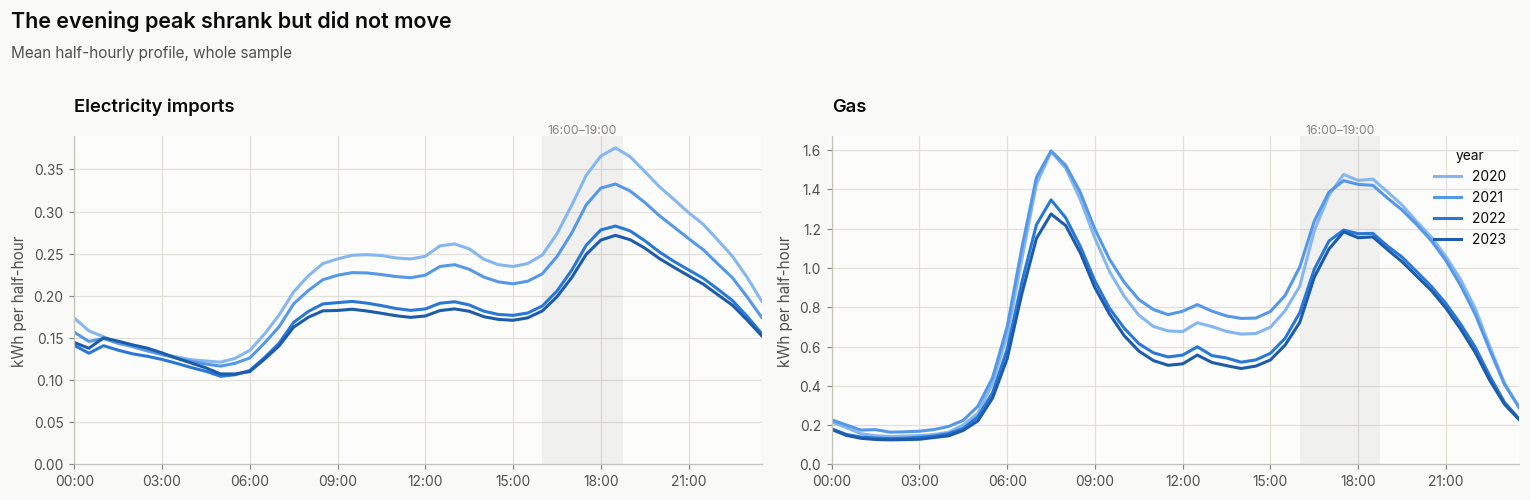

           quantity  year  kwh_per_day peak_time  peak_kwh_per_half_hour  peak_to_average  evening_peak_share_pct
Electricity imports  2020       11.025     18:30                   0.376            1.635                  17.360
Electricity imports  2021       10.083     18:30                   0.333            1.584                  17.013
Electricity imports  2022        8.682     18:30                   0.283            1.564                  16.641
Electricity imports  2023        8.499     18:30                   0.272            1.535                  16.350
                Gas  2020       37.656     07:30                   1.591            2.028                  20.829
                Gas  2021       39.116     07:30                   1.597            1.959                  20.253
                Gas  2022       30.831     07:30                   1.347            2.097                  20.911
                Gas  2023       29.498     07:30                   1.275            2.07

In [3]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, q in zip(axes, MAIN):
    ax.axvspan(32, 37.5, color=INK["muted"], alpha=0.10, lw=0)
    ax.text(34.75, 1.0, "16:00–19:00", transform=ax.get_xaxis_transform(), ha="center", va="bottom",
            fontsize=8, color=INK["muted"])
    for y in YEARS:
        p = serl.daily_profile(hh, y, q, "Wh", to_kwh=True)
        ax.plot(range(48), p.to_numpy(), color=YEAR_COLORS[y], label=str(y))
        rows.append({"quantity": q, "year": y, "kwh_per_day": p.sum(), "peak_time": p.idxmax(),
                     "peak_kwh_per_half_hour": p.max(), "peak_to_average": p.max() / p.mean(),
                     "evening_peak_share_pct": 100 * p.loc["16:00":"18:30"].sum() / p.sum()})
    plots.half_hour_axis(ax)
    ax.set_ylabel("kWh per half-hour"); ax.set_ylim(bottom=0)
    ax.set_title(q, loc="left", pad=16)
axes[1].legend(title="year", loc="upper right")
plots.figure_title(fig, "The evening peak shrank but did not move", "Mean half-hourly profile, whole sample")
reporter.save_fig(fig, "daily-profile-by-year")
plt.show()
profiles = pd.DataFrame(rows)
print(profiles.round(3).to_string(index=False))
reporter.save_table(profiles, "daily_profile_summary")

## 3. How unequal is use between households?

SERL reports, for each group, the mean, median and quartiles **across households**. A mean above the median and a positive quartile (Bowley) skewness mean that a minority of high users pulls the average up. The left chart shows each year's middle 50% of households (bar), median (white tick) and mean (dot); the right chart shows how that spread runs through the day.


Spread between households, 2023 (kWh/day)
                 quantity  households  mean  median    q1    q3    sd  mean_to_median  bowley_skew
      Electricity imports        8830  8.51    6.99  4.74 10.33  5.99            1.22         0.20
      Electricity exports        8480  0.01    0.00  0.00  0.00  0.26             NaN          NaN
          Electricity net        8830  8.50    6.99  4.73 10.31  6.00            1.22         0.19
                      Gas        7500 29.06   25.99 17.29 37.01 17.80            1.12         0.12
Gas + electricity imports        5540 34.77   31.62 20.72 44.48 20.56            1.10         0.08


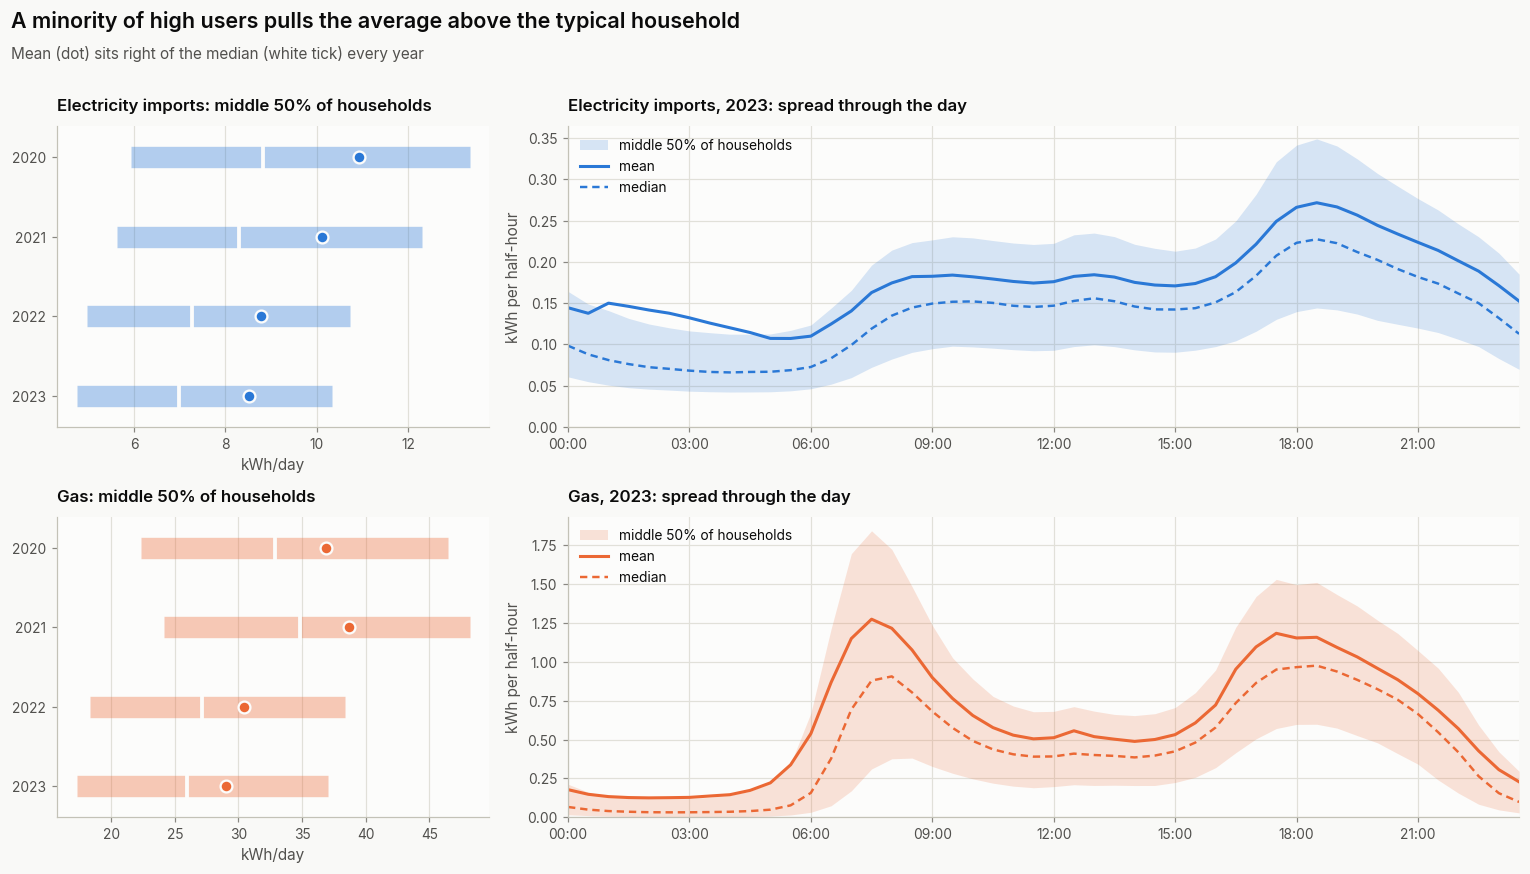

In [4]:
rows = []
for q in QUANTITIES:
    for y in YEARS:
        r = serl.select_slice(yearly[yearly["year"].eq(y)], q, "kWh/day").iloc[0]
        q1, med, q3 = r["25th_percentile"], r["median"], r["75th_percentile"]
        rows.append({"quantity": q, "year": y, "households": int(r["n_rounded"]), "mean": r["mean"], "median": med,
                     "q1": q1, "q3": q3, "sd": r["standard_deviation"],
                     "mean_to_median": r["mean"] / med if med else np.nan,
                     "bowley_skew": (q3 + q1 - 2 * med) / (q3 - q1) if q3 > q1 else np.nan})
spread = pd.DataFrame(rows)
print("Spread between households, 2023 (kWh/day)")
print(spread[spread["year"].eq(2023)].drop(columns="year").round(2).to_string(index=False))
reporter.save_table(spread, "spread_between_households")

fig, axes = plt.subplots(2, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 2.2]})
for row, (q, color) in zip(axes, MAIN.items()):
    ax = row[0]
    s = spread[spread["quantity"].eq(q)].set_index("year")
    ax.hlines(s.index, s["q1"], s["q3"], color=color, lw=14, alpha=0.35)
    ax.vlines(s["median"], s.index - 0.22, s.index + 0.22, color=COLORS["surface"], lw=2.5)
    ax.scatter(s["mean"], s.index, color=color, s=60, zorder=3, edgecolor=COLORS["surface"], linewidth=1.5)
    ax.set_yticks(YEARS); ax.invert_yaxis(); ax.set_xlabel("kWh/day"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{q}: middle 50% of households", loc="left", fontsize=11)
    ax = row[1]
    h = serl.select_slice(hh[hh["year"].eq(2023)], q, "Wh")
    ax.fill_between(range(48), h["25th_percentile"] / 1000, h["75th_percentile"] / 1000, color=color, alpha=0.18,
                    lw=0, label="middle 50% of households")
    ax.plot(range(48), h["mean"] / 1000, color=color, label="mean")
    ax.plot(range(48), h["median"] / 1000, color=color, ls=(0, (3, 2)), lw=1.6, label="median")
    plots.half_hour_axis(ax); ax.set_ylabel("kWh per half-hour"); ax.set_ylim(bottom=0)
    ax.set_title(f"{q}, 2023: spread through the day", loc="left", fontsize=11)
    ax.legend(loc="upper left")
plots.figure_title(fig, "A minority of high users pulls the average above the typical household",
                   "Mean (dot) sits right of the median (white tick) every year")
reporter.save_fig(fig, "spread-between-households")
plt.show()

## 4. Seasonal pattern

Mean daily use in each calendar month (whole sample), as a month × year heatmap: darker = more energy. **Look for:** gas is a winter fuel (about seven times higher in January than July); electricity varies far less; winter 2022–23 is lighter than winter 2020–21.


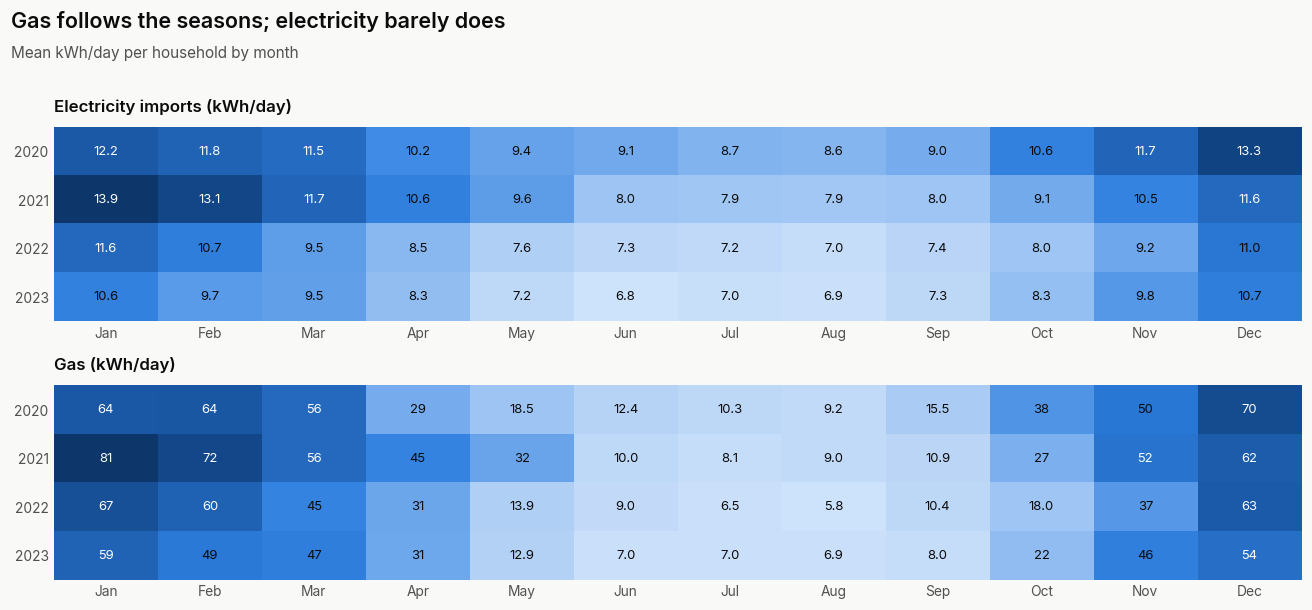

           quantity  year  winter_kwh_per_day  summer_kwh_per_day  winter_to_summer
Electricity imports  2020               12.44                8.82              1.41
Electricity imports  2021               12.87                7.97              1.61
Electricity imports  2022               11.11                7.16              1.55
Electricity imports  2023               10.31                6.91              1.49
                Gas  2020               65.95               10.63              6.20
                Gas  2021               71.53                9.05              7.90
                Gas  2022               63.32                7.11              8.91
                Gas  2023               53.89                6.96              7.75


In [5]:
MONTHS = "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()
rows = []
fig, axes = plt.subplots(2, 1, figsize=(12, 5.6))
for ax, q in zip(axes, MAIN):
    s = serl.monthly_series(monthly, q, "kWh/day")
    grid = pd.DataFrame({y: s.loc[str(y)].to_numpy() for y in YEARS}, index=MONTHS).T
    im = ax.imshow(grid, cmap=SEQUENTIAL_CMAP, aspect="auto")
    for (i, j), v in np.ndenumerate(grid.to_numpy()):
        dark = v > grid.to_numpy().min() + 0.6 * np.ptp(grid.to_numpy())
        ax.text(j, i, f"{v:.0f}" if v >= 20 else f"{v:.1f}", ha="center", va="center", fontsize=8.5,
                color=COLORS["surface"] if dark else INK["primary"])
    ax.set_xticks(range(12), MONTHS); ax.set_yticks(range(len(YEARS)), YEARS); ax.grid(False)
    ax.tick_params(length=0)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_title(f"{q} (kWh/day)", loc="left", fontsize=11)
    for y in YEARS:
        part = s.loc[str(y)]
        rows.append({"quantity": q, "year": y,
                     "winter_kwh_per_day": part[part.index.month.isin([12, 1, 2])].mean(),
                     "summer_kwh_per_day": part[part.index.month.isin([6, 7, 8])].mean()})
plots.figure_title(fig, "Gas follows the seasons; electricity barely does", "Mean kWh/day per household by month")
reporter.save_fig(fig, "monthly-use-heatmap")
plt.show()
season = pd.DataFrame(rows)
season["winter_to_summer"] = season["winter_kwh_per_day"] / season["summer_kwh_per_day"]
print(season.round(2).to_string(index=False))
reporter.save_table(season, "seasonality_by_year")

## 5. Differences by dwelling and household (2023)

For each level of eight SERL characteristics, mean daily use in 2023 compared with the whole-sample average (vertical line). Each stem runs from the average to the group; the thin bar is the 95% CI. Groups within one panel are disjoint, so they can be compared directly. **Look for:** floor area and occupants matter most; deprivation and tenure differences are smaller but consistent.


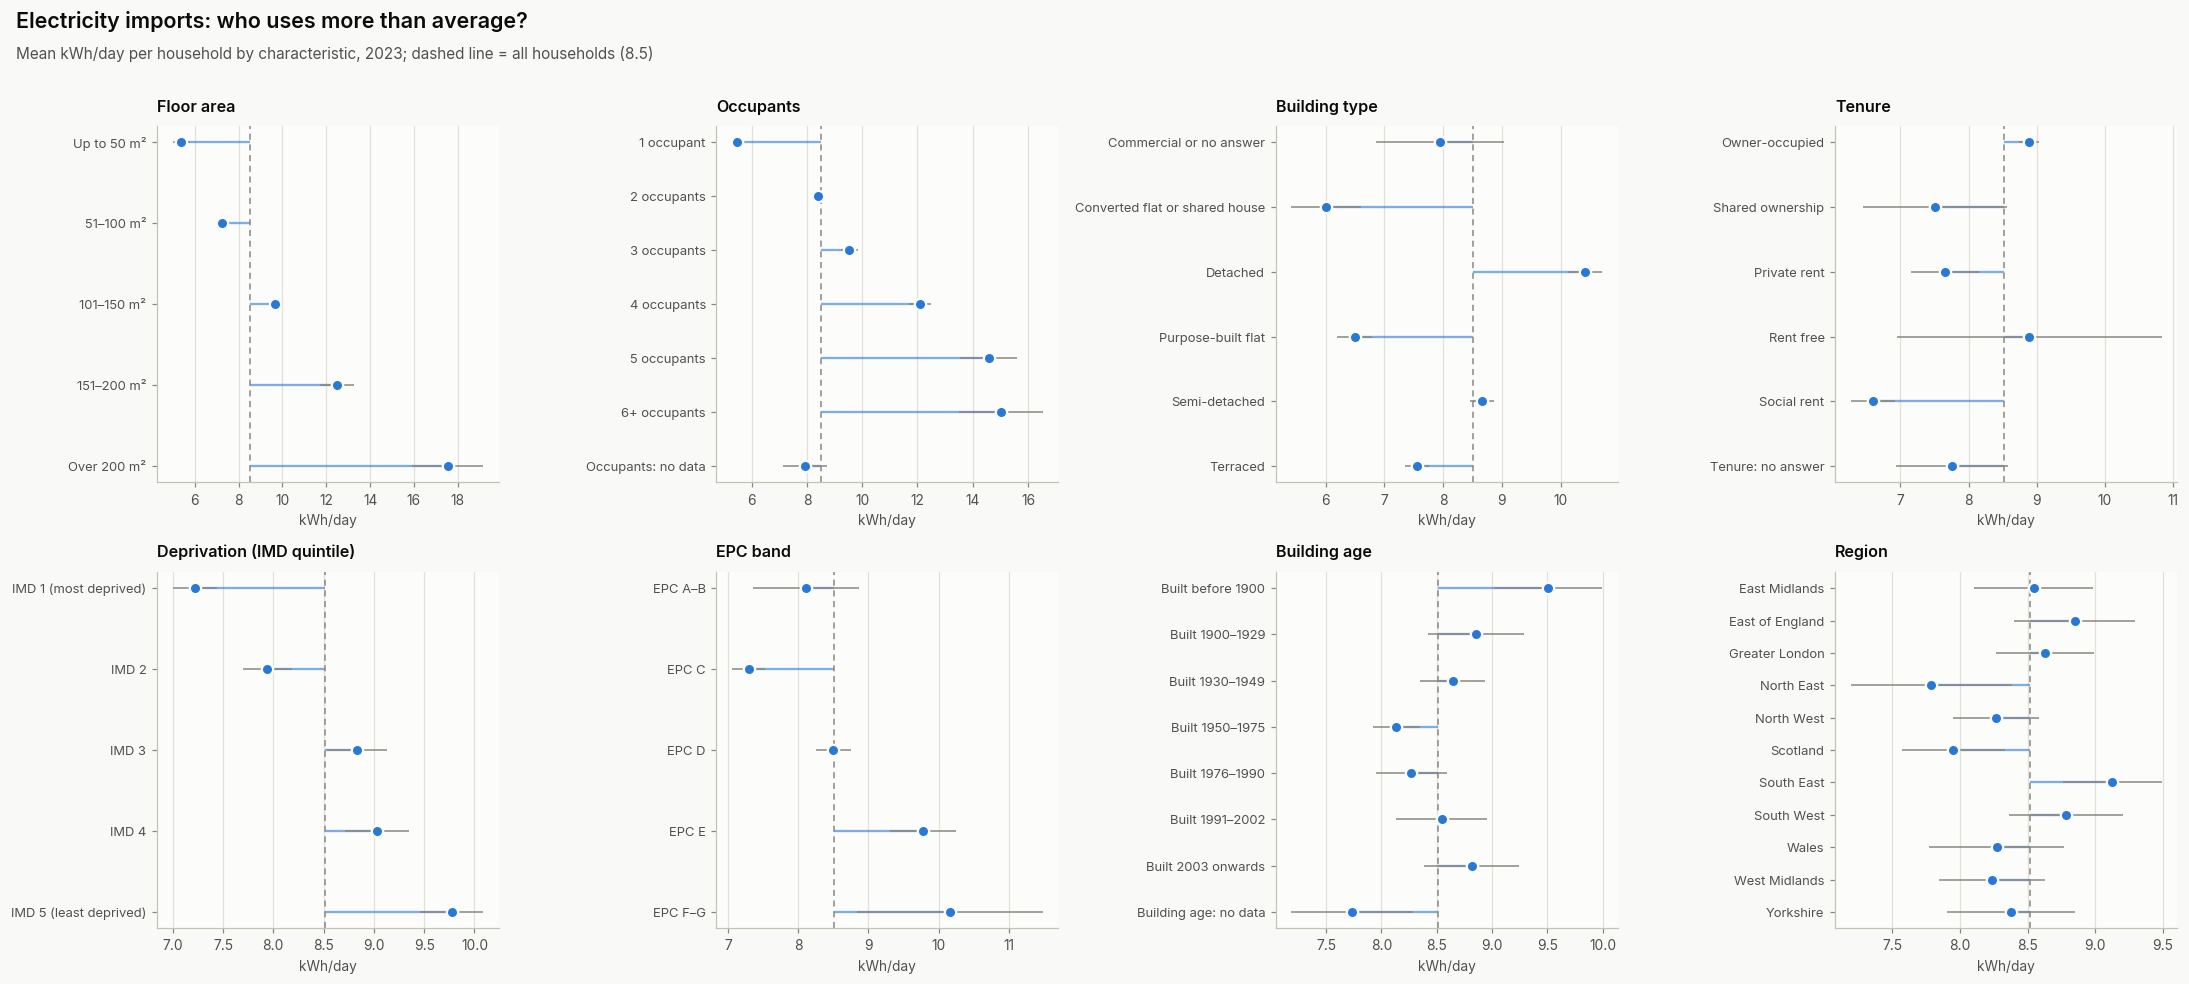

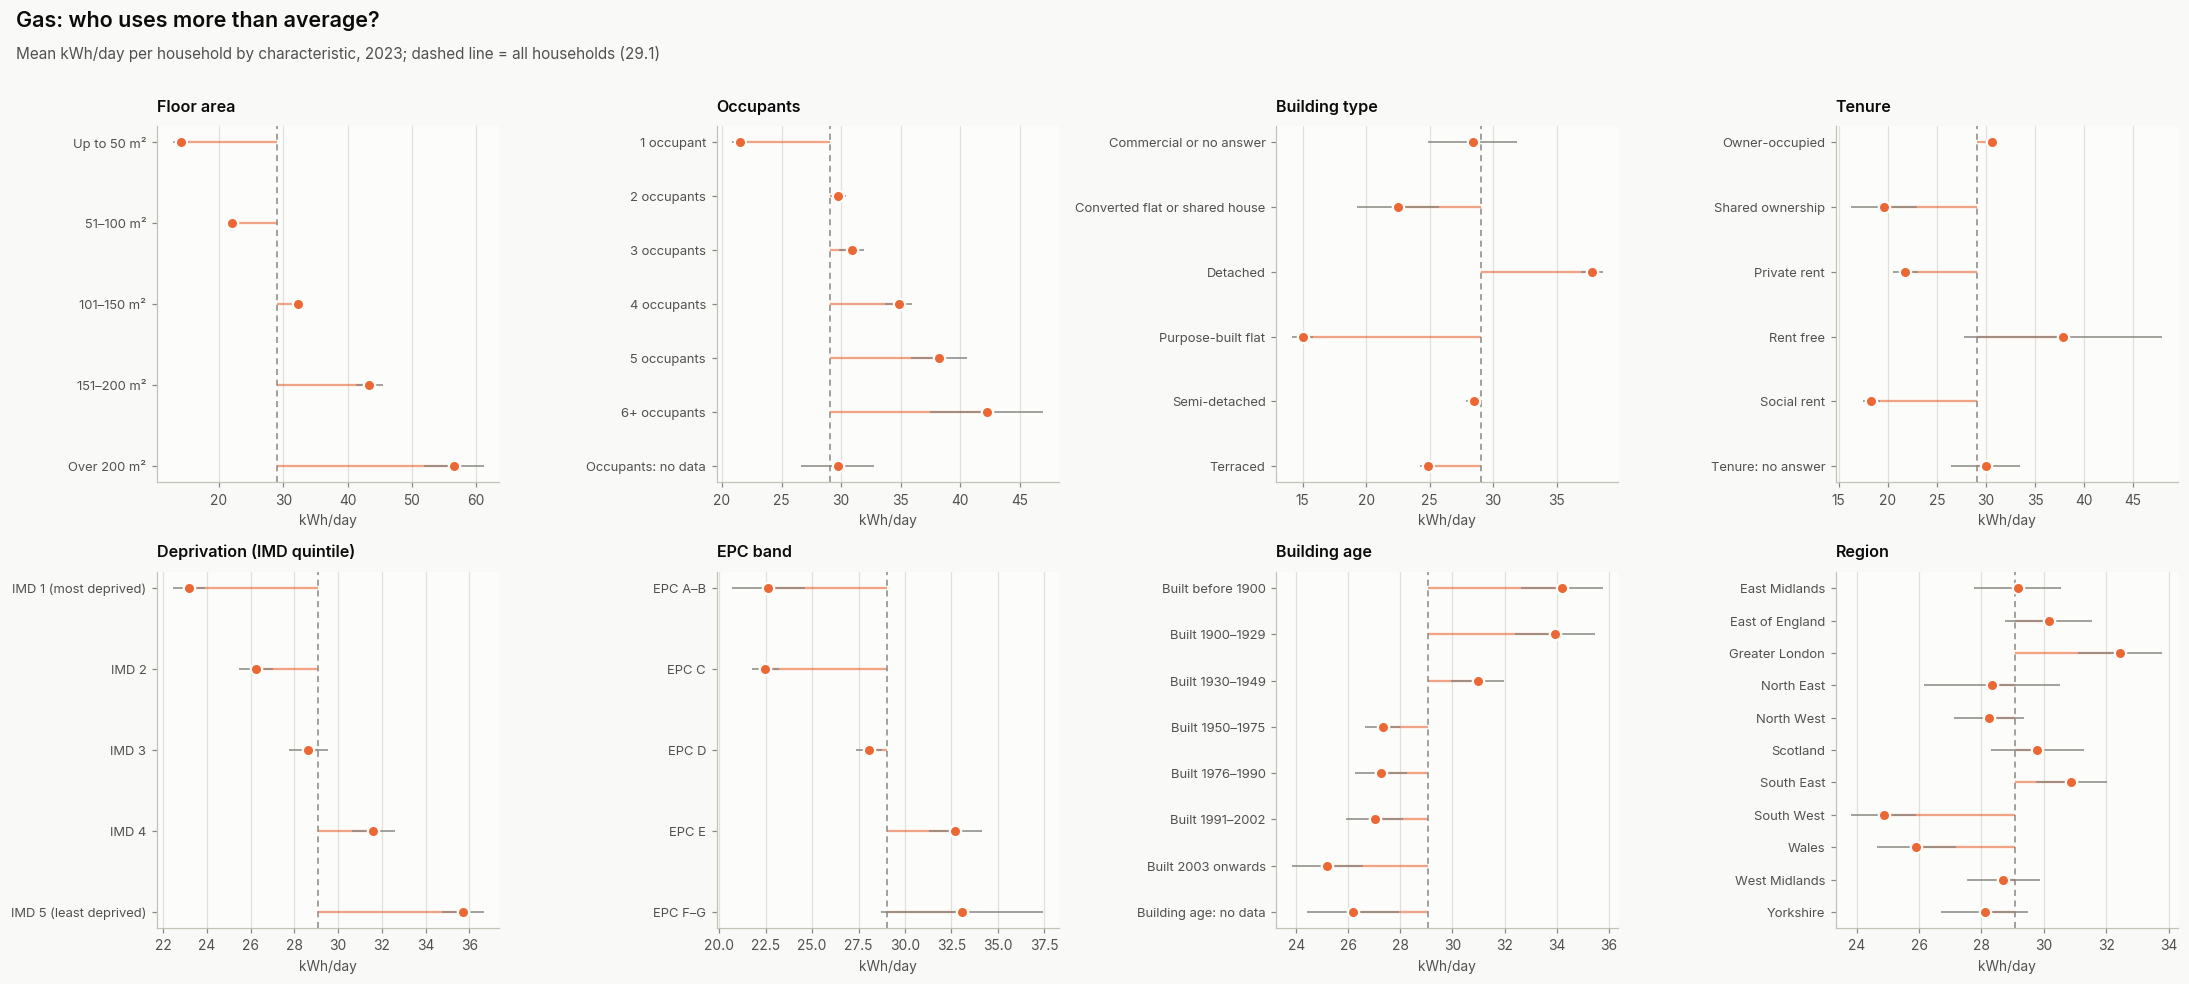

Ratio of highest to lowest level (2023)
quantity                    Electricity imports   Gas
characteristic                                       
Floor area                                 3.26  4.03
Building type                              1.73  2.52
Tenure                                     1.35  2.06
Occupants                                  2.75  1.96
Deprivation (IMD quintile)                 1.35  1.54
EPC band                                   1.39  1.47
Building age                               1.23  1.36
Region                                     1.17  1.30


In [6]:
PANELS = ["floor_area_m2", "num_occupants", "building_type", "tenure", "IMD_quintile", "currentEnergyRating",
          "building_age", "region"]
y23 = yearly[yearly["year"].eq(2023)]
rows = []
for q, color in MAIN.items():
    avg = serl.select_slice(y23, q, "kWh/day")["mean"].iloc[0]
    fig, axes = plt.subplots(2, 4, figsize=(20, 9))
    for ax, seg in zip(axes.flat, PANELS):
        s = serl.select_slice(y23, q, "kWh/day", segment=seg)
        s = s[~s["segment_3_value"].astype(str).isin(["All", "nan"])]
        s = s.set_index(s["segment_3_value"].astype(str))
        s = s.loc[ordered_levels(seg, list(s.index))]
        pos = np.arange(len(s))
        ax.hlines(pos, avg, s["mean"], color=color, lw=1.5, alpha=0.6)
        ax.hlines(pos, s["mean"] - 1.96 * s["standard_error_mean"], s["mean"] + 1.96 * s["standard_error_mean"],
                  color=INK["muted"], lw=1)
        ax.scatter(s["mean"], pos, color=color, s=55, zorder=3, edgecolor=COLORS["surface"], linewidth=1.5)
        ax.axvline(avg, color=INK["muted"], lw=1, ls=(0, (4, 3)))
        ax.set_yticks(pos, [level_label(seg, v) for v in s.index], fontsize=8.5)
        ax.invert_yaxis(); ax.grid(axis="y", visible=False)
        ax.set_title(SEGMENT_NAMES[seg], loc="left", fontsize=10.5); ax.set_xlabel("kWh/day", fontsize=9)
        for lv, r in s.iterrows():
            rows.append({"quantity": q, "characteristic": seg, "level": lv, "group_label": level_label(seg, lv),
                         "mean_kwh_per_day": r["mean"], "se": r["standard_error_mean"],
                         "households": int(r["n_rounded"]), "diff_from_average_pct": 100 * (r["mean"] / avg - 1)})
    plots.figure_title(fig, f"{q}: who uses more than average?",
                       f"Mean kWh/day per household by characteristic, 2023; dashed line = all households ({avg:.1f})")
    reporter.save_fig(fig, f"group-differences-{'electricity' if q.startswith('Elec') else 'gas'}-2023")
    plt.show()
gradients = pd.DataFrame(rows)
ratio = gradients.groupby(["quantity", "characteristic"])["mean_kwh_per_day"].agg(lambda v: v.max() / v.min())
print("Ratio of highest to lowest level (2023)")
print(ratio.unstack(0).rename(index=SEGMENT_NAMES).round(2).sort_values("Gas", ascending=False).to_string())
reporter.save_table(gradients, "group_differences_2023")

## 6. Weather by year

Mean outdoor temperature, heating degree days and solar irradiance experienced by SERL households (whole sample). 2021 was the coldest year, which explains part of its higher gas use.


In [7]:
w = serl.select_slice(yearly, "Gas", "kWh/day").set_index("year")[["mean_temp", "mean_hdd", "mean_solar"]]
w.columns = ["mean_temp_c", "heating_degree_days_per_day", "solar_irradiance"]
print(w.round(2).to_string())
reporter.save_table(w, "weather_by_year", index=True)

      mean_temp_c  heating_degree_days_per_day  solar_irradiance
year                                                            
2020        11.02                         5.17            125.87
2021        10.41                         5.71            121.29
2022        11.31                         5.05            126.20
2023        11.19                         5.06            121.72


## Conclusions

- **Demand fell by about a fifth from 2020 to 2023**, almost all of it in 2022: electricity imports 10.9 → 8.5 kWh/day and gas 36.9 → 29.1 kWh/day per household.
- **The timing did not change.** The electricity peak stayed at 18:30 every year, and the 16:00–19:00 share only slipped from 17.4% to 16.4%.
- **A minority of high users lifts the average:** the mean is 12–22% above the median for both fuels.
- **Gas is seasonal, electricity much less so:** winter gas is 6–9 times summer gas; winter electricity about 1.5 times summer.
- **Size and household make-up matter most:** use rises steeply with floor area and occupants; deprivation and tenure gaps are smaller but consistent.

## Limitations

- Group-level statistics: one characteristic at a time, no household-level links, so differences are not adjusted for each other (e.g. larger homes are less often in deprived areas).
- The sample roughly tripled between 2020 and 2021; part of the 2020→2021 change can be a change in who is measured (checked in 4.2).
- Electricity exports reflect very few PV homes after 2021 and are not interpreted.
